# Deep Network Development, 2026 Autumn - Week 8 Practice - **Notebook for video recording**

## Loading data and converting it into a NumPy array

**Database:** We will continue working with the dataset introduced last week, the Titanic Dataset - https://www.kaggle.com/datasets/yasserh/titanic-dataset .

In [ ]:

titanic_csv_url = 'https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv'


### Dataset CSV file loading - Option 2: Using the built-in `csv` module of Python

_(Taken from Week 7 without changes)_

**We will first download the dataset file** and then open it as a local file. In certain environments (e.g., Google Colab) bash commands can be executed from Jupyter notebook cells.

In [ ]:

# You need to do this when using Google Colab: download file to Colab disk by using the bash command 'wget'
#!wget https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv



--2026-10-30 21:12:35--  https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv
Resolving nipg12.inf.elte.hu (nipg12.inf.elte.hu)... 157.181.160.172
Connecting to nipg12.inf.elte.hu (nipg12.inf.elte.hu)|157.181.160.172|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 61194 (60K) [text/csv]
Saving to: ‘titanic.csv’

titanic.csv         100%[===================>]  59.76K   250KB/s    in 0.2s    

2026-10-30 21:12:36 (250 KB/s) - ‘titanic.csv’ saved [61194/61194]



**Opening the file**, converting it to a nested list of strings using the built-in Python `csv` module and then, **converting this into a nested list of numeric values.**

In [ ]:
import csv

with open('titanic.csv', 'r') as file:
    my_reader = csv.reader(file, delimiter=',')
    attr_names = next(my_reader)
    print(attr_names)

    sex_dict = {'female': 0, 'male': 1}
    embarked_dict = {'C': 0, 'Q': 1, 'S': 2}

    dataset = []
    for row in my_reader:
        dataset_row = []
        for item_idx, item in enumerate(row):
            item = item.strip()
            if item_idx in {1, 2, 5, 6, 7, 9}:
                val = float('nan') if item == '' else float(item)
            elif item_idx == 4:
                val = sex_dict[item]
            elif item_idx == 11:
                val = float('nan') if item == '' else embarked_dict[item]
            else:
                continue
            dataset_row.append(val)
        dataset.append(dataset_row)


['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


**Converting the nested list into a 2D NumPy array** and then **separating** the column of binary classification **labels** (survival information) into the `labels` 1D array **and** placing all remaining columns into the `inputs` 2D array which will be used as **input information** to our neural network.

In [ ]:

import numpy as np

dataset_arr = np.array(dataset, dtype=np.float32)
print(dataset_arr[:5])
print(dataset_arr.shape)

inputs = dataset_arr[:,1:]
print(f"inputs array shape: {inputs.shape}, dtype: {inputs.dtype}")
print(inputs[:5, :])
labels = dataset_arr[:,0].astype(np.int32)
print(f"labels array shape: {labels.shape}, dtype: {labels.dtype}")
print(labels[:5])

[[ 0.      3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 1.      3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      1.      0.     35.      1.      0.     53.1     2.    ]
 [ 0.      3.      1.     35.      0.      0.      8.05    2.    ]]
(891, 8)
inputs array shape: (891, 7), dtype: float32
[[ 3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      0.     35.      1.      0.     53.1     2.    ]
 [ 3.      1.     35.      0.      0.      8.05    2.    ]]
labels array shape: (891,), dtype: int32
[0 1 1 1 0]


## The pre-processing of the data for learning

<font color='red'>**Please note:** Only those pre-procesisng steps are implemented now which were discussed last week. The additional steps introduced here are intentionally not implemented - **these are left to you to implement them.** </font>

### Handling missing values

First, **we handle missing values**, as neural networks are not able to naturally handle missing values unlike some other machine learning models (e.g., decision trees). Additionally, the final dataset should not have any NaN (or positive/negative infinity) values left as this would break numeric computations performed during neural network training and inference.

**Various alternatives are available to handle missing values:**
- Replace all NaN values by zeros. Not ideal. - **Implemented below.**
- Replace missing values with specifically chosen numeric values. This value can be the variable mean, median or some constant chosen for some specific reason.
- If the variable is a categorical one, we can also create a new category for the missing values.
- Add an extra "flag" variable to the dataset which indicates whether the value of the original variable is a valid value or a missing value. Additionally, replace all NaN values of the original variable with an arbitrary value (e.g., zero).
- Drop entire data points or entire variables which have missing values.

There are several things to consider when choosing a technique:
- If we are to train the model:
    - If we are training a model and want to accustom it to missing data marked in a specific way, the best approach is probably to create a new binary flag variable to indicate missing values in the original variable. An individual flag variable should be created for each variable that may have missing values. If our variable is categorical, we can also choose to create a new category for missing values. As will be discussed later in this notebook, however, categorical variables should preferably be converted to the one-hot format. With one-hot conversion, introducing a new category is logically very similar to simply creating a new binary variable to flag missing values.
    - The other approaches listed above for representing missing values are problematic. For example, if we set the variable value to a specific constant to indicate a missing value, this constant could interfere with the variable's actual values. In this case, the model would not be able to tell whether we are indicating a missing or real value. For instance, using the mean of the variable to replace missing values could affect real values if they are close to the mean. However, if we choose the median, we are more likely to experience interference because the median is an actual value of the variable if the number of data points is odd. Dropping all data points and/or variables with missing values is another option; however, if we do that, our model will not become accustomed to them during training.
- If we have a trained model that has not encountered missing values during training and we wish to use it for inference on data with missing values:
    - In this case, we cannot change the model's architecture, especially if it is an MLP, as there is a fixed set of weights associated with each input variable. Consequently, dropping a variable or adding a new flag variable is no longer possible.
    - It is possible to replace missing values with a specific constant. However, we must understand an important rule about the behaviour of neural networks. If the neural network is given input values that differ significantly from the training data (i.e. are 'out of distribution'), the network's estimates will be undefined. It is possible that the variable we are setting is very significant in the decision-making process learnt by the network, in which case there could be large weights associated with it. Setting such a variable with an out-of-distribution value could result in extremely inaccurate predictions, even if the values of the other variables are typical. For this reason, we should not choose a constant to represent missing values that is not typical of the actual data.
    -  The mean of a variable is often present among its values, but not always. For example, if we have a binary variable and the network has only seen 0s and 1s during training, a mean value of 0.6 would not be typical. In this case, selecting the middle value from the sorted sequence of values would be better, as it was at least a typical value during training. If there is an odd number of data points, this is identical to the median value. However, it is important to note that just because a certain value is typical for a specific variable in the data, it is still possible that, for such a manipulated data point, the combination of values for all variables will be outside the joint distribution of the variables and lead to undefined behaviour. Additionally, interference of the meaning remains an issue when missing values are replaced with a specific 'typical' constant.


In [ ]:

print("How many NaNs are in the `inputs` array?", np.count_nonzero(np.isnan(inputs)))
print("How many NaNs are in the `labels` array?", np.count_nonzero(np.isnan(labels)))

inputs[np.isnan(inputs)] = 0.                 # An alternative specifically for NaN values: inputs = np.nan_to_num(inputs, nan=0.)

print("\nHow many NaNs are in the `inputs` array now?", np.count_nonzero(np.isnan(inputs)))


How many NaNs are in the `inputs` array? 179
How many NaNs are in the `labels` array? 0

How many NaNs are in the `inputs` array now? 0


The logic behind implementing the alternatives:
- **Replacing a certain constant value in an 1D array with another constant:** Create a mask from the array indicating equality with the old constant value. Index into the array with this mask to overwrite the selected locations with the new constant value. The new constant can come from some operation of course: `np.mean(my_array)` will provide the mean of the array. If we would like to ignore the old constant values during the mean computation, we can mask the array before applying the mean function.
- **Replacing NaNs:** The mask indicating NaN positions can be created by `np.isnan(my_array)`. Using the equality operator does not work in this case as equality with NaN values is always false.
- **Collapse operations ignoring NaNs:** Some collapse operations have a version which ignores NaN values. E.g., `np.nanmean()`, `np.nanmedian()`, `np.nanmin()`, `np.nanmax()`, etc.
- **Creating a flag variable to indicate NaN values in a column of a 2D array:** A mask can be directly used as a flag variable. If we need floating point data type for the flag values, we can convert the mask by using `ndarray.astype(np.float32)`, for example. False values become 0, True values become 1. The new flag variable can be added or inserted into the 2D dataset as a new column by using slicing and concatenation.
- **Handling multiple columns at the same time - replacing certain (e.g., NaN) values with their own column means:**
    - The mean of each row/column of a 2D array can be computed by `np.mean()` with specifying the `axis` parameter. If we need to ignore NaN values, `np.nanmean()` can be used. Many other collapse operations have a "NaN" version. If we need to ignore values other than NaNs (with arbitrary mask):
        - we can either copy the array and overwrite the values to ignore with NaNs and apply `np.nanmean()` or similar operations.
        - or for certain operations, like `np.mean()`, a `where` parameter can be passed which should be a mask specifying the locations not to ignore in the array.
    - Using the mean of the own row/column of the specific missing value to replace it is not trivial, as when we try to overwrite certain elements of a 2D array with a 2D mask (e.g., `my_2d_array[my_2d_mask] = values_to_write_into_array`), the right-hand side of the assignment (`values_to_write_into_array`) should list the values to write in as a sequence, but the corresponding row and column locations are not present there. Instead we can try the following appraoches:
        - `out = np.where(condition_mask, source_if_true, source_if_false)`: The function `np.where()` can be used slightly differently if 3 parameters are specified. `out` will be an array with values coming from both `source_if_true` and `source_if_false`. The `condition_mask` mask decides that the value at the corresponding location in `out` will be taken from `source_if_true` or `source_if_false`. The easiest to imagine how it works is with arguments of equal shapes. However, that is not necessary, the argument shapes need to be compatible by broadcasting only. This way, we can specify a 2D mask and overwrite certain values with it by placing the row/column means in `source_if_true`.
        - The row/column indices of True elements in the mask can be extracted with `np.where(mask)`. The resulting integer index arrays can be used to index the elements of the original array on the left hand side of an assignment and the column averages on the right hand side of the assignment.
- **Dropping rows or columns where certain values (e.g., NaNs) are present:** Masks can be created along one or multiple dimensions as a result of equality check against the missing value. Then, we can use these masks (or there logical negation) to index into the dataset array to only keep rows / columns with valid values.

### Identification and conversion of categorical variables

Next, we need to **identify if there are any variables which are of categorical type**. Categorical variables can take a finite, usually very limited number of possible values only and these values have no natural ordering. In our case, the sex of the passenger ("Sex") and the port of embarkation ("Embarked") are such variables. The various categories are encoded as different integer values.

- 'Embarked' has three valid categories, but for some passengers, this value was missing. In the previous step, a suitable way to handle the missing values in this column was to create a new category for them. However, it is not ideal to represent independent categories with no natural ordering using integer indices. In our case, the three possible ports of embarkation (Cherbourg, Queenstown and Southampton) were originally encoded with the values 0, 1 and 2. This type of representation could suggest that the cities have a natural ordering, with Queenstown falling between Cherbourg and Southampton. When there is no natural ordering of the categories, we should not expect our model to assume a correlation between the values of the category indices and the responses associated with the categories. **We usually try to avoid this type of index-based representation for multi-class categorical labels and use one-hot encoding instead. The same approach should be taken for input variables.** As we now have three categories (four when a new category is included for missing values), the 'Embarked' variable should be replaced with three (four) new binary variables, each representing the presence of one of the possible categories. For each passenger, exactly one of these three (four) new variables would have a value of 1, with all other values being 0.

- The "Sex" column is a binary variable (having two categories only) already, so there is no need to convert it to one-hot.

There are various approaches to **converting a 1D array of integer indices into a 2D array of one-hot vectors.** Three of these approaches are covered in Week 4 worksheet, Exercise 4.3.

### Random reordering of data points

With tabular datasets, **we often have no information about how the rows (data points) are ordered**. Sometimes this is randomized on purpose. However, more often than not, there is some non-arbitrary logic to the order. Before applying a machine learning model to a dataset, one of the pre-processing steps involves splitting the dataset into training, validation and test sets. If the dataset is ordered in a specific way by default, the distribution of the data may differ for two consecutive intervals taken from the row indices of the dataset. In this case, our model will adapt to the different distribution of data within the training set and may not function correctly when the trained model is applied to the test set or other unseen data. For example, it could be possible, that the passengers in the Titanic dataset are arranged in order of embarkation. If the dataset is split using the slicing method, the test set could potentially only contain passengers who boarded at the last port visited before the ocean crossing began. This could cause the evaluation results for the test set to be biased.

To ensure that the distribution of data in different parts of the dataset is consistent, **we should randomly rearrange the order of the data points,** which in our case means randomly shuffling the passengers in the dataset.

Several approaches can be taken:
- If we only need to reorder a single array along one or multiple axes, we can use `np.random.shuffle()`. This function always shuffles the order along the first axis. In a 2D array, this corresponds to the reordering of the rows. When this is not suitable for us, we can transpose and/or reshape the array before the shuffling and in the end, perform the inverse of the transformations. The function performs the shuffling in-place, modifying the contents of the specified array.
- When we do not want to modify the original array, we can just create a copy.
- If we wish to reorder mutliple arrays using a consistent permutation, we can either concatenate / stack together the arrays and perform shuffling over this new array. What is usually even more convenient is to create a random permutation using `np.random.permutation()` and use this permutation as an integer index array to index into each array along the appropriate axis.
    - `np.random.permutation(10)`, for example will create an identical array to the randomly shuffled result of `np.arange(10)`. This will list the indices from 0 to 9 in a random order, and can be used to index into our dataset along the first axis (the passengers axis) to reorder the rows / passengers.
    - We can also specify a list or an array to `np.random.permutation()`. In this case, the result will be a randomly shuffled copy of the original argument.
    - To produce a random permutation, the result of `np.arange()` can also be shuffled with `np.random.shuffle()`.

When working with random numbers in NumPy, the more modern approach is to create a new `np.random.Generator` object first, optionally with a manually specified seed, this way:

```
>>> rng = np.random.default_rng(12345)
```

Then, the Generator object can be used with the functions mentioned above. For example:

```
>>> my_perm = rng.permutation(10)
>>> my_perm
array([1, 7, 4, 3, 0, 9, 2, 5, 8, 6])     # random
```

Creating two Generator objects with the same seed value will produce the same results for function calls in the same order. This enables seemingly random behaviour to be made reproducible.

### Checking the distribution of labels and, if necessary, balancing the dataset

In both regression tasks, where the labels are continuous variables, and classification tasks, where the labels are categorical variables, **it is important to analyze the distribution of the label variables: the frequency of possible label values.** It is also essential to understand how a certain distribution may influence the training and evaluation results of our model.

Within the training set, the frequency of possible label values influences the behaviour of the trained model. For example, consider a binary classification dataset where the two possible label values are "cats" and "dogs", and the training dataset consists of 100 examples, 80 of which are in the "cat" category and 20 of which are in the "dog" category. In this case, we can say that our dataset is seriously imbalanced with respect to the label distribution, meaning that the label category distribution is highly non-uniform.

**If we train our model on such an imbalanced dataset, it will learn this distribution as a 'bias' and be more likely to predict the most common category later.**

The same thing can happen in regression, but since we don't have discrete categories, we can talk about the probability density of the label variable. For example, if we train our model to estimate people's ages and there are more young people in our training set, the model will usually estimate a younger age, even when the evaluation data is balanced and contains a uniform mix of young and old people.

Why is this the case? By default, the loss function averages over the training set or a minibatch of examples sampled from the training set. If the model tends to misidentify a certain proportion of young people as older, it will be penalized more by the loss function than if it misidentifies the same proportion of older people as younger (as the younger age group is overrepresented in the training set).

Additionally, if our model is underfitting - meaning that it is not yet properly trained, or its architecture is too simple to model the relationships in the data appropriately - then, in the case of an imbalanced training set, it is very likely that the model will prefer to estimate the majority category or frequent label values, even more so than the training data distribution would suggest. This issue arises from the problem with loss mentioned earlier: when the model is not confident in its prediction, it is safer to estimate the majority label, as this will result in a lower loss value, as fewer mistakes will have been made. To illustrate this, take an imbalanced classification dataset and a suitable neural network model, and train the model. However, during training, instead of passing the actual input variable values to the model, replace them with some random, arbitrary values. The model will then have no information about which label category to predict. In this case, the safest choice is to predict the majority category 100% of the time. In practice, when we train our model on real data, there will still be some remaining lack of confidence, so it is very likely that the trained model will prefer to predict the majority category more frequently than it actually occurs in the data. If the trained model predicts only a single category, this could indicate that the model is underfitting, has not been properly trained yet, or is not complex enough. An imbalanced dataset will even amplify the frequency of this phenomenon.

**So, should we balance the distribution of labels in our dataset?** The answer depends on a number of factors. Firstly, will the trained model be used on data with a similar imbalanced distribution to the training set? If yes, it may not be a good idea to balance the data to achieve a uniform label distribution before training. In this case, the model would be biased towards a uniform distribution, which does not reflect the actual distribution of the data. However, maintaining the imbalanced distribution can also cause problems, as previously mentioned: the trained model will likely over-predict the majority class. A better approach would be to resample the dataset so that minority categories or less frequent label values become more frequent without enforcing a uniform distribution.


Different (simple) approaches to balancing the label distribution:
- **Resampling the data**
    - **Creating a balanced dataset by resampling the data prior to training:** In classification datasets, we can either drop examples from the majority categories or duplicate examples in the minority categories to achieve uniform number of examples falling into the different categories. Dropping data is usually not preferred. If we are talking about a regression problem, the bins of a histogram can be used instead of categories. Based on this, some data points can be dropped, some can be duplicated.
    - **Producing balanced mini-batches during training:** Often, the preferred approach to balancing the data is to leave the original dataset unchanged,however, during training, the mini-batch iteration can be modified so that it does not simply go through the data points sequentially or randomly select them by uniform sampling, but instead selects data points which, when considered together, produce a mini-batch with a balanced label distribution.
    - **Implementation:** Performing these techniques in software code rely on random sampling functions. In NumPy, we can select the indices of data points randomly with `np.random.randint()` or `np.random.choice()`. With `np.random.randint()`, we can randomly generate many integers between two specified integers, for example, between 0 and the length of the dataset with a uniform sampling distribution. With `np.random.choice()`, we can do the same thing, or we can specify a list or an array to select multiple elements randomly from these collections. Here, we can also assign probabilities to each integer or each element in the list or array so a non-uniform sampling is even more easy to implement. `np.random.choice()` has the `replace` parameter which can be set to `False` to make sure that there are no duplicates in the returned random sample ( - can only be ensured when we are undersampling, i.e., the sample is smaller than the source array).
- **Weighted loss**
    - Instead of resampling the data, we can also specify weights for the individual data points when calculating the total (average) loss value. For example, if we have 80 examples with the "cat" label and 20 examples with the "dog" label and we would like to perform a completely balanced training, we can take the loss values corresponding to the individual examples and mutliply those that belong to a dog by 4, before averaging the per-example loss values across the minibatch. This will penalize the mistakes of the neural network seriously when estimating the labels for "dog" examples. As a result, the neural network will be expected to learn to handle cats and dogs equally well, instead of focusing on the majority category, the cats.
    - **Implementation:** When using popular loss functions in PyTorch, like `torch.nn.MSELoss`, `BCELoss` or `CrossEntropyLoss`, we can specify the `reduction="none"` argument. By default, the `"mean"` argument is used for the `reduction` parameter and that will result in the averaging of the per-example loss values over the batch of provided data points and thus the result of the function is a simple scalar loss value. When we pass the `"none"` argument, however, the per-example loss values are kept and returned, so we will get a tensor of per-example loss values returned, matching in numbers with the batch size. Now, we can manually apply per-example weights with simple element-wise multiplication and then we can perform the reduction (collapse) using the `torch.mean()` function to get the total average loss in a scalar form. We of course have to make sure during the multiplication with the weights that broadcasting is executed appropriately. If the model predictions are provided to the loss function in a shape of `(batch_size, 1)`, for example, multiplying it with a weights tensor in the shape of `(batch_size,)` will perform an incorrect operation (resulting in a `(batch_size, batch_size)` shaped tensor) without raising an error.

**When labels are imbalanced, appropriate metrics need to be used.** Standard accuracy will show the accuracy considering the distribution of data in the training set.

There are additional techniques that can be applied to a neural network that has already been trained on data with a given distribution as a post-processing step. If we want to use the model to predict labels for data with a different distribution to that of the training data, we can modify the model's outputs in a specific way to increase the predicted probabilities for certain categories and decrease them for others. Examples of such methods include Platt scaling, temperature scaling and histogram binning. These will not be discussed in this class.



### Splitting the dataset into training/validation/test sets


Splitting the dataset to training/validation/test sets.


**Alternatives**
- Proportions can be specified - **Implemented below.**
- The size of one or multiple of the sets can be specified as an integer (e.g., there will be 500 training data points). The sets with unspecified sizes can possibly distribute the remaining data points evenly.

In [ ]:
# dataset split through basic indexing
#    alternative: scikit-learn - sklearn.model_selection.train_test_split()

TRAINING_SET_RATIO = 0.6
VALIDATION_SET_RATIO = 0.2
assert TRAINING_SET_RATIO + VALIDATION_SET_RATIO < 1

n_training_samples = int(inputs.shape[0] * TRAINING_SET_RATIO)
n_validation_samples = int(inputs.shape[0] * VALIDATION_SET_RATIO)
validation_offset = n_training_samples
test_offset = n_training_samples + n_validation_samples

inputs_train = inputs[:validation_offset, :]
labels_train = labels[:validation_offset]
inputs_val = inputs[validation_offset:test_offset, :]
labels_val = labels[validation_offset:test_offset]
inputs_test = inputs[test_offset:, :]
labels_test = labels[test_offset:]

print(f"Training inputs shape: {inputs_train.shape}, labels shape: {labels_train.shape}")
print(f"Validation inputs shape: {inputs_val.shape}, labels shape: {labels_val.shape}")
print(f"Test inputs shape: {inputs_test.shape}, labels shape: {labels_test.shape}")


Training inputs shape: (534, 7), labels shape: (534,)
Validation inputs shape: (178, 7), labels shape: (178,)
Test inputs shape: (179, 7), labels shape: (179,)


### Feature scaling

As discussed in one of the lectures, if the input variables take values from completely different ranges, the loss function can become severely distorted as a result. When gradient-based optimization methods (e.g., SGD) are used to minimize such loss function values, the gradients (i.e., the parameter update steps) will usually not point towards the solution, but instead will oscillate. As a result, it will take many more steps to reach a certain loss level compared to the case when an ideally shaped loss function is used. Additionally, it is often necessary to reduce the step sizes (i.e., the learning rate), otherwise convergence will not happen.

To avoid these issues, **the input variables can be linearly rescaled to span similar ranges on the number line.** Two methods were discussed during lecture:
- Min-max rescaling
- Standardization

In both approaches, it is **important to scale the variables independently,** as otherwise, using common scalers, the relative difference between the ranges of variables would not change. These techniques were featured as NumPy exercises in the worksheet of a prior practice class.

Besides scaling the input variables, **such techniques can also be motivated when performing regression with multiple label variables with different statistics.** For example, if we use the MSE loss function to estimate two label variables with widely different value ranges (distributions) by averaging the squared errors of the two estimates, the label variable with the higher deviation will be expected to have higher corresponding errors. Consequently, a unit relative error in this variable will affect the loss significantly more than in the other variable. Consequently, the neural network will focus much more on learning to predict this variable appropriately than the other one. To prevent this, we should either apply scaling to the label variables independently of each other or use appropriate weights before averaging the losses of the two label variables.

### The order of these pre-processing steps

The necessity of these pre-processing steps should be considered individually in view of the particularities of the dataset. Some steps may be more appropriate in certain cases than others. The order in which these steps are applied can also be a subject of discussion. As mentioned during the lectures, the test set should be reserved for the final evaluation and quality assurance of our trained model. This means that we should not use the test set for training or model / hyperparameter selection and should not have access to its statistics during training. Therefore, if we take this restriction seriously, it is best to separate the test set from the rest of the data to be used for training and validation at the very beginning. When applying pre-processing steps, these steps should not depend on information taken from the test set. For example, when applying feature scaling on the input variables, we should compute the mean and deviation (or the minimum and maximum) of the variables based only on the training and validation sets, and apply these scaling parameters to the test set later.

<font color='red'>**Please note:** Only the same pre-processing steps as last week are actually implemented. For best results, the other steps described above should also be implemented.</font>

## Converting the dataset arrays to tensors

_(Taken from Week 7 without changes)_

In [ ]:

import torch


As we will use PyTorch to train neural networks, we need to convert the `inputs` and `labels` arrays to `torch.Tensor` type objects.

In [ ]:

inputs_train_t = torch.tensor(inputs_train, dtype=torch.float32)     # Input data types should be torch.float32
inputs_val_t = torch.tensor(inputs_val, dtype=torch.float32)
inputs_test_t = torch.tensor(inputs_test, dtype=torch.float32)
labels_train_t = torch.tensor(labels_train, dtype=torch.float32)     # For binary classification, the labels are "true probabilities": either 0 or 1. Data type should be torch.float32.
labels_val_t = torch.tensor(labels_val, dtype=torch.float32)
labels_test_t = torch.tensor(labels_test, dtype=torch.float32)

print(inputs_train_t.shape)
print(inputs_train_t[:5, :])
print(labels_train_t.shape)
print(labels_train_t[:5])


torch.Size([534, 7])
tensor([[ 3.0000,  1.0000, 22.0000,  1.0000,  0.0000,  7.2500,  2.0000],
        [ 1.0000,  0.0000, 38.0000,  1.0000,  0.0000, 71.2833,  0.0000],
        [ 3.0000,  0.0000, 26.0000,  0.0000,  0.0000,  7.9250,  2.0000],
        [ 1.0000,  0.0000, 35.0000,  1.0000,  0.0000, 53.1000,  2.0000],
        [ 3.0000,  1.0000, 35.0000,  0.0000,  0.0000,  8.0500,  2.0000]])
torch.Size([534])
tensor([0., 1., 1., 1., 0.])


## Defining a simple MLP neural network for the binary classification task

_(Taken from Week 7 without changes)_

The `torch.nn` module contains high-level building blocks that helps us implement and use neural networks.

In [ ]:

import torch.nn as nn
import matplotlib.pyplot as plt        # needed for loss curve plotting later


To define a custom neural network architecture, we need to create a subclass for the `torch.nn.Module` class.
The main components of the `torch.nn.Module` class which we need to overload in our subclass:
- **The `__init__()` method:** We need to specify the components of our neural network here, especially those which have parameters to train (e.g., layers).
- **The `forward()` method:** This is the actual implementation of the hypothesis function. The method describes the steps needed to evaluate the network using the inputs to get the label predictions.

Below, we define a 3-layer Multi-layer Perceptron (MLP) neural network.

In [ ]:

class BinClassifierMLP(nn.Module):

  def __init__(self, n_input_vars):
        super().__init__()
        self.linear1 = nn.Linear(n_input_vars, 30)
        self.linear2 = nn.Linear(30, 20)
        self.linear3 = nn.Linear(20, 1)            # Binary classification: A single neuron in the last layer

  def forward(self, x):
      # print(x.shape)                  # (batch_size, n_input_vars)
      h = self.linear1(x)
      # print(h.shape)                  # (batch_size, 30)
      h = nn.functional.relu(h)
      h = self.linear2(h)
      h = nn.functional.relu(h)
      h = self.linear3(h)
      h = nn.functional.sigmoid(h)      # Binary classification: Sigmoid at the end
      return h


The same definition using the `torch.nn.Sequential` class as a list-like container for the layers.

In [ ]:

class BinClassifierMLP(nn.Module):

  def __init__(self, n_input_vars):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_input_vars, 30),
            nn.ReLU(),
            nn.Linear(30, 20),
            nn.ReLU(),
            nn.Linear(20, 1),           # Binary classification: A single neuron in the last layer
            nn.Sigmoid()                # Binary classification: Sigmoid at the end
        )

  def forward(self, x):
    return self.layers(x)


An alternative model for binary classification: A single neuron with a sigmoid (a logistic regression).

In [ ]:

class LogisticRegressionModel(nn.Module):

  def __init__(self, n_input_vars):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_input_vars, 1),        # Binary classification: A single neuron in the last (and only) layer
            nn.Sigmoid()                       # Binary classification: Sigmoid at the end
        )

  def forward(self, x):
      return self.layers(x)


**Instantiating** our neural network (or logistic regression) model.

In [ ]:
MODEL_TO_USE = 'mlp'
assert MODEL_TO_USE in ['logreg', 'mlp']

if MODEL_TO_USE == 'logreg':
    bincl_model = LogisticRegressionModel(n_input_vars=inputs_train.shape[1])
elif MODEL_TO_USE == 'mlp':
    bincl_model = BinClassifierMLP(n_input_vars=inputs_train.shape[1])


## Training the neural network

Besides the standard Binary Cross-entropy (BCE) loss, we would like to measure the performance of the model using the **binary accuracy metric** too. This metric is easier to interpret for a human: the ratio of correctly classified examples.

We now define this metric manually.

_(Taken from Week 7 without changes)_

In [ ]:

@torch.no_grad()
def bin_acc_fn(y_hat, y_true):                                 # An accuracy metric only suitable for binary classification
    # y_hat: (batch_size, 1) single probability, y_true: (batch_size, 1) float32 in {0,1}
    assert y_hat.shape == y_true.shape
    return torch.count_nonzero(torch.round(y_hat) == y_true) / y_hat.shape[0]


### Training - Option 1: Minibatch iteration implemented with a simple loop

First, we implement the mini-batch iteration with a simple loop and tensor slicing. We will run the training for a total of 50 epochs. In each epoch, we go through the training set once by mini-batch iteration, then evaluate the performance of the model on the validation set too. No early stopping is used yet. Following the training procedure, we evaluate the performance of the trained model on the test set. Finally, we plot the training and validation curves for the BCE loss and binary accuracy metric values measured in each epoch.

_(Taken from Week 7 without changes)_

/tmp/ipykernel_4163/263472326.py:36: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  train_losses_in_epoch = torch.tensor(train_losses_in_epoch)


Epoch #0, tr loss: 0.7316348552703857, val loss: 0.6471788287162781, tr acc: 0.5494652390480042, val acc: 0.6539351940155029
Epoch #1, tr loss: 0.665016233921051, val loss: 0.6277312636375427, tr acc: 0.6266711354255676, val acc: 0.6695601940155029
Epoch #2, tr loss: 0.6559584736824036, val loss: 0.6226348280906677, tr acc: 0.6266711354255676, val acc: 0.6851851940155029
Epoch #3, tr loss: 0.6464901566505432, val loss: 0.6136009097099304, tr acc: 0.6458890438079834, val acc: 0.6996528506278992
Epoch #4, tr loss: 0.6438915133476257, val loss: 0.6087941527366638, tr acc: 0.6514037847518921, val acc: 0.6996528506278992
Epoch #5, tr loss: 0.6396985054016113, val loss: 0.603821337223053, tr acc: 0.6514037847518921, val acc: 0.694444477558136
Epoch #6, tr loss: 0.6365615725517273, val loss: 0.6001169681549072, tr acc: 0.6595922112464905, val acc: 0.6840278506278992
Epoch #7, tr loss: 0.6340557336807251, val loss: 0.5960304141044617, tr acc: 0.6540775299072266, val acc: 0.6840278506278992
Epo

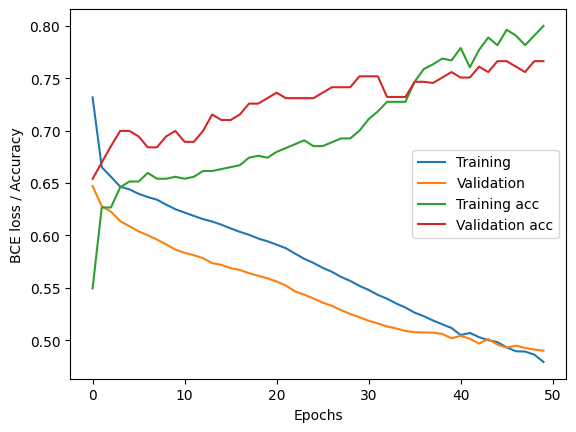

In [ ]:
loss_fn = nn.BCELoss()

n_epochs = 50                           # Now, we will iterate for a fixed number of epochs. We will add early stopping later...
learning_rate = 0.001
batch_size = 32
optimizer = torch.optim.Adam(bincl_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []

for epoch_idx in range(n_epochs):

    # training
    bincl_model.train()                  # just setting a flag (setting our neural network model in a training mode)
    train_losses_in_epoch = []
    train_accs_in_epoch = []

    for offset_idx in range(0, inputs_train_t.shape[0], batch_size):
        end_offset_idx = min(offset_idx + batch_size, inputs_train_t.shape[0])
        train_batch_xs = inputs_train_t[offset_idx:end_offset_idx, :]        # (batch_size OR smaller_last_batch_size, n_input_vars)
        train_batch_ys = labels_train_t[offset_idx:end_offset_idx, None]     # (batch_size OR smaller_last_batch_size, 1)

        optimizer.zero_grad()
        train_batch_ys_pred = bincl_model(train_batch_xs)        # (batch_size OR smaller_last_batch_size, n_input_vars) -> (batch_size OR smaller_last_batch_size, 1)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)      # 'loss' always has to be a scalar
        acc = bin_acc_fn(train_batch_ys_pred, train_batch_ys)    # scalar

        train_losses_in_epoch.append(loss)
        train_accs_in_epoch.append(acc)

        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    train_accs_in_epoch = torch.tensor(train_accs_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_tr_epoch_acc = train_accs_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)
    train_accuracy.append(avg_tr_epoch_acc)

    # validation
    bincl_model.eval()                  # just setting a flag (setting our neural network model in a non-training mode)
    val_losses_in_epoch = []
    val_accs_in_epoch = []

    for offset_idx in range(0, labels_val_t.shape[0], batch_size):
        end_offset_idx = min(offset_idx + batch_size, labels_val_t.shape[0])
        val_batch_xs = inputs_val_t[offset_idx:end_offset_idx, :]
        val_batch_ys = labels_val_t[offset_idx:end_offset_idx, None]

        with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
            val_batch_ys_pred = bincl_model(val_batch_xs)
        loss = loss_fn(val_batch_ys_pred, val_batch_ys)
        acc = bin_acc_fn(val_batch_ys_pred, val_batch_ys)

        val_losses_in_epoch.append(loss)
        val_accs_in_epoch.append(acc)

    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    val_accs_in_epoch = torch.tensor(val_accs_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_val_epoch_acc = val_accs_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)
    val_accuracy.append(avg_val_epoch_acc)

    # logging
    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

    # (end of training loop)

print("Training finished.")

# training has finished; evaluate trained model on test set (measure loss, accuracy on test set)
test_ys_preds = []
for offset_idx in range(0, labels_test_t.shape[0], batch_size):               # if the whole test set evaluation fits into memory, no need to do batches here, can be done in one go
    end_offset_idx = min(offset_idx + batch_size, labels_test_t.shape[0])
    test_batch_xs = inputs_test_t[offset_idx:end_offset_idx, :]
    test_batch_ys = labels_test_t[offset_idx:end_offset_idx, None]

    with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
        test_batch_ys_pred = bincl_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)

test_ys_preds = torch.cat(test_ys_preds, axis=0)
test_loss = loss_fn(test_ys_preds, labels_test_t[:,None])
test_acc = bin_acc_fn(test_ys_preds, labels_test_t[:,None])

print(f"Test loss: {test_loss}, test acc: {test_acc}")

# Plot training/val curves
plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss / Accuracy')
plt.legend()
plt.show()


### Training - Option 2: Minibatch iteration implemented with a custom iterator

Another, more general option for implementing a training loop is by using iterators. In this case the batch creation code is not placed directly in the loop, but an iterator will be responsible for the creation of batches. Here, we only implement the consecutive slicing of the dataset split to batches of data point inputs and labels. For this, practically we can use the same piece of code that performs the dataset slicing, but we will hide it inside an iterator. However, batch generation can happen in various other ways. It is, for example, possible to randomly sample data points from the dataset. The random sampling can also happen in many ways. We can perform a balanced training with respect to the label categories, for example, by randomly choosing an equal number of data points from each category to construct batches. We will not implement random sampling here, but instead, the iterator will perform the consecutive slicing.

In Python 3, an iterable type can be implemented by a class that has an `__iter__()` member function (or alternatively, a `__getitem__()` member function). Iterable types include standard, built-in container types (list, tuple, set, dictionary, etc.) and allows the sequential enumeration of their elements using iterators. The `__iter__()` member function of these types must return an iterator that iterates over the elements of the container (usually once). Therefore, an iterator is representing a bookmark within the iterable: it must know at what element it is currently at and which element should be listed next. Formally, the iterator type can be implemented by a class that has a `__next__()` member function. This function is responsible for returning the next element, so the iterator must know its current position inside the iterable object. When an iterator reached the end of the iteration, it should raise a `StopIteration` exception. When, for example the iteration is used in a for loop, this exception will indicate that the iteration ended and it is time to exit the loop.

For convenience reasons, it is preferred that an iterator also implements the `__iter__()` member function and usually this simply returns `self`, the current instance.

This time, we will only implement a stateful iterator that can be used for a single iteration over the tensors which are passed to it in the class initialization method. After the iterator was used for a single full iteration of mini-batches over the dataset tensor, it expires and for another round of iteration a new instance needs to be created from the class. An alternative would be to implement an additional, iterable class besides `MinibatchIterator`, where each `__iter__()` call could return a new `MinibatchIterator` instance. We will skip the implementation of this second class now.

The tensor slicing to create batches is implemented in `__next__()`. This returns the batch of input variable values and the corresponding batch of labels (wrapped in a tuple of length 2).

In [ ]:

# One instance of this class can be used for one full iteration of the dataset, then it expires

class MinibatchIterator:

  def __init__(self, input_split, labels_split, batch_size):
    self.input_split = input_split
    self.labels_split = labels_split
    self.batch_size = batch_size
    self.offset_idx = 0

  def __iter__(self):
    return self

  def __next__(self):
    if self.offset_idx < self.input_split.shape[0]:
      batch_xs = self.input_split[self.offset_idx:self.offset_idx+self.batch_size, :]
      batch_ys = self.labels_split[self.offset_idx:self.offset_idx+self.batch_size, None]
      self.offset_idx += self.batch_size
      return batch_xs, batch_ys
    else:
      raise StopIteration()



A more convenient and compact way to define iterators is by using generators. Like iterators, generators can be advanced step by step; the `generator` object implements both `__iter__()` and `__next__()`. A generator's `yield` statement is similar to `return` in a function, but after yielding a value it suspends its own execution and returns control to the context that called `__next__()` on the generator. While suspended, it preserves the values of its local variables. Next time the `__next__()` is called on the generator, execution resumes from the previous `yield` statement and and continues, until it encounters another `yield`. A generator terminates only when it reaches a `return` statement or the end of its scope.

Now, let's implement the iterator class defined above, `MinibatchIterator`, as a generator!

In [ ]:
def minibatch_generator(input_split, labels_split, batch_size):
    # input_split: (n_samples, n_features), labels_split: (n_samples,)
    assert input_split.shape[:1] == labels_split.shape
    for offset_idx in range(0, input_split.shape[0], batch_size):
        batch_xs = input_split[offset_idx:offset_idx+batch_size, :]
        batch_ys = labels_split[offset_idx:offset_idx+batch_size, None]
        yield batch_xs, batch_ys                        # Note: we can check the tensor shapes/contents returned by the generator with a for loop or with a next() call


**Re-initializing** our neural network (or logistic regression) model for the new training.

In [ ]:
MODEL_TO_USE = 'mlp'
assert MODEL_TO_USE in ['logreg', 'mlp']

if MODEL_TO_USE == 'logreg':
    bincl_model = LogisticRegressionModel(n_input_vars=inputs_train.shape[1])
elif MODEL_TO_USE == 'mlp':
    bincl_model = BinClassifierMLP(n_input_vars=inputs_train.shape[1])


We modify the training loop to sample the batches from the iterator instead of slicing it manually from the dataset tensor, inside the loop.

Epoch #0, tr loss: 0.7502144575119019, val loss: 0.6341279149055481, tr acc: 0.574364960193634, val acc: 0.6371527910232544
Epoch #1, tr loss: 0.6574368476867676, val loss: 0.6001443266868591, tr acc: 0.6246657371520996, val acc: 0.6996528506278992
Epoch #2, tr loss: 0.6431117057800293, val loss: 0.59881192445755, tr acc: 0.6393716335296631, val acc: 0.6892361640930176
Epoch #3, tr loss: 0.6412665247917175, val loss: 0.5970179438591003, tr acc: 0.6467245817184448, val acc: 0.694444477558136
Epoch #4, tr loss: 0.6344570517539978, val loss: 0.5925610065460205, tr acc: 0.6540775299072266, val acc: 0.6996528506278992
Epoch #5, tr loss: 0.6325926780700684, val loss: 0.5879214406013489, tr acc: 0.6540775299072266, val acc: 0.7048611640930176
Epoch #6, tr loss: 0.6290416717529297, val loss: 0.5850144028663635, tr acc: 0.6540775299072266, val acc: 0.7048611640930176
Epoch #7, tr loss: 0.6272709369659424, val loss: 0.5827545523643494, tr acc: 0.6540775299072266, val acc: 0.710069477558136
Epoch

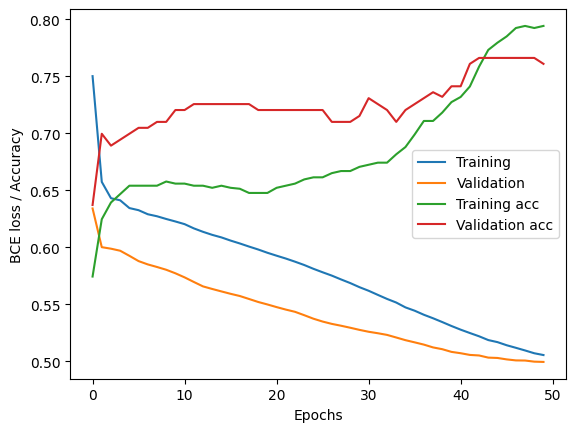

In [ ]:
loss_fn = nn.BCELoss()

n_epochs = 50                           # Now, we will iterate for a fixed number of epochs. We will add early stopping later...
learning_rate = 0.001
batch_size = 32
optimizer = torch.optim.Adam(bincl_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []

for epoch_idx in range(n_epochs):

    # training
    bincl_model.train()                  # just setting a flag (setting our neural network model in a training mode)
    train_losses_in_epoch = []
    train_accs_in_epoch = []

    # minibatch_iterator = MinibatchIterator(inputs_train_t, labels_train_t, batch_size)           # The class-based alternative
    # for train_batch_xs, train_batch_ys in minibatch_iterator:
    for train_batch_xs, train_batch_ys in minibatch_generator(inputs_train_t, labels_train_t, batch_size):      # The generator-based alternative

        optimizer.zero_grad()
        train_batch_ys_pred = bincl_model(train_batch_xs)        # (batch_size OR smaller_last_batch_size, n_input_vars) -> (batch_size OR smaller_last_batch_size, 1)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)      # 'loss' always has to be a scalar
        acc = bin_acc_fn(train_batch_ys_pred, train_batch_ys)    # scalar

        train_losses_in_epoch.append(loss)
        train_accs_in_epoch.append(acc)

        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    train_accs_in_epoch = torch.tensor(train_accs_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_tr_epoch_acc = train_accs_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)
    train_accuracy.append(avg_tr_epoch_acc)

    # validation
    bincl_model.eval()                  # just setting a flag (setting our neural network model in a non-training mode)
    val_losses_in_epoch = []
    val_accs_in_epoch = []

    # minibatch_iterator = MinibatchIterator(inputs_val_t, labels_val_t, batch_size)           # The class-based alternative
    # for val_batch_xs, val_batch_ys in minibatch_iterator:
    for val_batch_xs, val_batch_ys in minibatch_generator(inputs_val_t, labels_val_t, batch_size):      # The generator-based alternative

        with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
            val_batch_ys_pred = bincl_model(val_batch_xs)
        loss = loss_fn(val_batch_ys_pred, val_batch_ys)
        acc = bin_acc_fn(val_batch_ys_pred, val_batch_ys)

        val_losses_in_epoch.append(loss)
        val_accs_in_epoch.append(acc)

    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    val_accs_in_epoch = torch.tensor(val_accs_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_val_epoch_acc = val_accs_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)
    val_accuracy.append(avg_val_epoch_acc)

    # logging
    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

    # (end of training loop)

print("Training finished.")

# training has finished; evaluate trained model on test set (measure loss, accuracy on test set)
test_ys_preds = []
test_ys = []         # CHANGED: now collecting the true test label batches from the iterator and not using the original dataset tensor


# minibatch_iterator = MinibatchIterator(inputs_test_t, labels_test_t, batch_size)           # The class-based alternative
# for test_batch_xs, test_batch_ys in minibatch_iterator:
for test_batch_xs, test_batch_ys in minibatch_generator(inputs_test_t, labels_test_t, batch_size):      # The generator-based alternative

    with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
        test_batch_ys_pred = bincl_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)
        test_ys.append(test_batch_ys)

test_ys_preds = torch.cat(test_ys_preds, axis=0)
test_ys = torch.cat(test_ys, axis=0)
test_loss = loss_fn(test_ys_preds, test_ys)
test_acc = bin_acc_fn(test_ys_preds, test_ys)

print(f"Test loss: {test_loss}, test acc: {test_acc}")

# Plot training/val curves
plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss / Accuracy')
plt.legend()
plt.show()


### Training - Option 3: Relying on the `Dataset` and `DataLoader` classes of PyTorch

Finally, another, more common way to implement mini-batch iteration is by using the built-in classes of PyTorch: `torch.utils.data.Dataset` and `torch.utils.data.DataLoader`.

First, we define our dataset by subclassing `torch.utils.data.Dataset`. We should override the `__getitem__()` member function, which is called whenever the `Dataset` object is indexed. The index is passed to `__getitem__()`. In our implementation `__getitem__()` should be able to handle a simple integer index and return the corresponding element of the dataset: the input values and the label for a single passenger wrapped into a tuple. We must also implement `__len__()`, which defines and returns the length of the dataset whenever `len(my_dataset_object)` is called.

`DataLoader` can also be subclassed if needed, but this time, its default functionality is enough for us. A `DataLoader` object can sample batches of data points from a `Dataset` instance and it also supports random sampling. For this, we pass the `shuffle=True` argument to the data loader. The default `shuffle=False` would result in consecutive slicing.


In [ ]:

from torch.utils.data import Dataset, DataLoader

# Custom Dataset subclass for binary classification
class BinaryClassificationDataset(Dataset):
    def __init__(self, input_split, labels_split):
        self.xs = torch.tensor(input_split, dtype=torch.float32)
        self.ys = torch.tensor(labels_split, dtype=torch.float32)
        # (true) labels dtypes:
        #     Binary classification: float32 (a single probability for each data point)

    def __len__(self):
        return self.xs.shape[0]

    # Note: Not the most efficient if data is small, batches are large (so that __getitem__ is called many times)
    def __getitem__(self, idx):
        return self.xs[idx, :], self.ys[idx, None]      # returning: (tensor(n_input_vars,), tensor(1,))
                                                        #   --> DataLoader will yield: (tensor(batch_size, n_input_vars), tensor(batch_size, 1))



We create one instance from our new `Dataset` subclass as a wrapper for each of the three dataset splits. We also create three `DataLoader` instances building onto the three corresponding `Dataset` instances.

In [ ]:

train_dataset = BinaryClassificationDataset(inputs_train, labels_train)
val_dataset = BinaryClassificationDataset(inputs_val, labels_val)
test_dataset = BinaryClassificationDataset(inputs_test, labels_test)

dataloader_train = DataLoader(train_dataset, batch_size=32, shuffle=True)
dataloader_val = DataLoader(val_dataset, batch_size=32, shuffle=True)
dataloader_test = DataLoader(test_dataset, batch_size=32, shuffle=False)     # no need to randomly sample batches when evaluating


**Re-initializing** our neural network (or logistic regression) model for the new training.

In [ ]:
MODEL_TO_USE = 'mlp'
assert MODEL_TO_USE in ['logreg', 'mlp']

if MODEL_TO_USE == 'logreg':
    bincl_model = LogisticRegressionModel(n_input_vars=inputs_train.shape[1])
elif MODEL_TO_USE == 'mlp':
    bincl_model = BinClassifierMLP(n_input_vars=inputs_train.shape[1])


As `DataLoader` is an iterable, it can be used in a for loop: it will provide iterators. The shape of tensors (or sometimes scalars) returned by the `__getitem()__` of the Dataset must be appropriate: the DataLoader will take multiple of these tensors (`batch_size` number of them) and stack them together along a new, first axis. If a scalar is returned by the Dataset, the DataLoader will place these in a 1D tensor.

Therfore, in case of the binary classification task, if `Dataset.__getitem__()` returns the input values of a data point as a tensor of shape `(n_input_vars,)` and the label as a tensor of shape `(1,)`, the corresponding DataLoader instance will stack a batch of them together so that its iterator will return a tensor of shape `(batch_size, n_input_vars)` for the inputs and a tensor of shape `(batch_size,)` for the labels.

In case of other tasks, these shapes may be different. We will cover those cases next week.

Finally, we train the newly initialized neural network using the iterators of the DataLoaders in the inner for loops.

Epoch #0, tr loss: 0.7620616555213928, val loss: 0.67169189453125, tr acc: 0.5797125697135925, val acc: 0.6267361044883728
Epoch #1, tr loss: 0.6674734354019165, val loss: 0.6537671685218811, tr acc: 0.6422125697135925, val acc: 0.6695601940155029
Epoch #2, tr loss: 0.6539815068244934, val loss: 0.6365678310394287, tr acc: 0.6415441036224365, val acc: 0.6932870745658875
Epoch #3, tr loss: 0.6406208276748657, val loss: 0.6257283687591553, tr acc: 0.6460561156272888, val acc: 0.7048611640930176
Epoch #4, tr loss: 0.6328955292701721, val loss: 0.6168563961982727, tr acc: 0.6595922112464905, val acc: 0.6799768805503845
Epoch #5, tr loss: 0.6331886649131775, val loss: 0.6389146447181702, tr acc: 0.6540775299072266, val acc: 0.6458333134651184
Epoch #6, tr loss: 0.6229693293571472, val loss: 0.6031413674354553, tr acc: 0.6659425497055054, val acc: 0.6851851940155029
Epoch #7, tr loss: 0.6276423931121826, val loss: 0.6174370646476746, tr acc: 0.6669451594352722, val acc: 0.7008101940155029
Ep

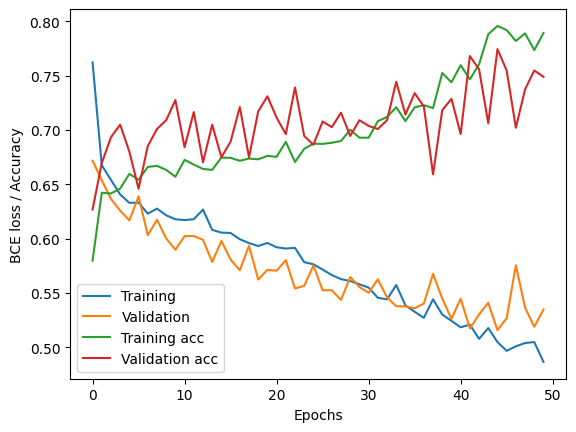

In [ ]:
loss_fn = nn.BCELoss()

n_epochs = 50                           # Now, we will iterate for a fixed number of epochs. We will add early stopping later...
learning_rate = 0.001
batch_size = 32
optimizer = torch.optim.Adam(bincl_model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracy = []
val_accuracy = []

for epoch_idx in range(n_epochs):

    # training
    bincl_model.train()                  # just setting a flag (setting our neural network model in a training mode)
    train_losses_in_epoch = []
    train_accs_in_epoch = []

    for train_batch_xs, train_batch_ys in dataloader_train:      # the DataLoader instance is an iterable; it provides a new iterator on an __iter__() call

        optimizer.zero_grad()
        train_batch_ys_pred = bincl_model(train_batch_xs)        # (batch_size OR smaller_last_batch_size, n_input_vars) -> (batch_size OR smaller_last_batch_size, 1)
        loss = loss_fn(train_batch_ys_pred, train_batch_ys)      # 'loss' always has to be a scalar
        acc = bin_acc_fn(train_batch_ys_pred, train_batch_ys)    # scalar

        train_losses_in_epoch.append(loss)
        train_accs_in_epoch.append(acc)

        loss.backward()
        optimizer.step()

    train_losses_in_epoch = torch.tensor(train_losses_in_epoch)
    train_accs_in_epoch = torch.tensor(train_accs_in_epoch)
    avg_tr_epoch_loss = train_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_tr_epoch_acc = train_accs_in_epoch.mean()
    train_losses.append(avg_tr_epoch_loss)
    train_accuracy.append(avg_tr_epoch_acc)

    # validation
    bincl_model.eval()                  # just setting a flag (setting our neural network model in a non-training mode)
    val_losses_in_epoch = []
    val_accs_in_epoch = []

    for val_batch_xs, val_batch_ys in dataloader_val:      # the DataLoader instance is an iterable; it provides a new iterator on an __iter__() call

        with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
            val_batch_ys_pred = bincl_model(val_batch_xs)
        loss = loss_fn(val_batch_ys_pred, val_batch_ys)
        acc = bin_acc_fn(val_batch_ys_pred, val_batch_ys)

        val_losses_in_epoch.append(loss)
        val_accs_in_epoch.append(acc)

    val_losses_in_epoch = torch.tensor(val_losses_in_epoch)
    val_accs_in_epoch = torch.tensor(val_accs_in_epoch)
    avg_val_epoch_loss = val_losses_in_epoch.mean()    # not exactly precise because of last (possibly) incomplete batch
    avg_val_epoch_acc = val_accs_in_epoch.mean()
    val_losses.append(avg_val_epoch_loss)
    val_accuracy.append(avg_val_epoch_acc)

    # logging
    print(f"Epoch #{epoch_idx}, tr loss: {avg_tr_epoch_loss}, val loss: {avg_val_epoch_loss}, tr acc: {avg_tr_epoch_acc}, val acc: {avg_val_epoch_acc}")

    # (end of training loop)

print("Training finished.")

# training has finished; evaluate trained model on test set (measure loss, accuracy on test set)
test_ys_preds = []
test_ys = []         # CHANGED: now collecting the true test label batches from the iterator and not using the original dataset tensor

for test_batch_xs, test_batch_ys in dataloader_test:      # the DataLoader instance is an iterable; it provides a new iterator on an __iter__() call

    with torch.no_grad():                      # no need to compute gradients for validation predictions/losses
        test_batch_ys_pred = bincl_model(test_batch_xs)
        test_ys_preds.append(test_batch_ys_pred)
        test_ys.append(test_batch_ys)

test_ys_preds = torch.cat(test_ys_preds, axis=0)
test_ys = torch.cat(test_ys, axis=0)
test_loss = loss_fn(test_ys_preds, test_ys)
test_acc = bin_acc_fn(test_ys_preds, test_ys)

print(f"Test loss: {test_loss}, test acc: {test_acc}")

# Plot training/val curves
plt.plot(train_losses, label='Training')
plt.plot(val_losses, label='Validation')
plt.plot(train_accuracy, label='Training acc')
plt.plot(val_accuracy, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss / Accuracy')
plt.legend()
plt.show()


We reach a binary accuracy of around 80% on the test set. **The results are hard to interpret as we haven't accounted for the non-uniform distribution of categories** (the different number of passengers surviving and dying).

We will continue to improve our procedure next week.